# <font color='#3b4859'><b>Les réseaux de neurones convolutifs avec PyTorch - Application</b></font>

Bienvenue dans le suite du cours sur les fondamentaux du Deep Learning. Dans ce notebook, vous allez via PyTorch :
- construire un Convolutional Neural Network (CNN) ou Réseau de neurones convolutif en français.
- entraîner le modèle
- utiliser le transfer learning

# <font color='#3b4859'>1. Import des librairies et des données</font>

Dans cet exercice pratique, nous allons utiliser un dataset connu en Computer-Vision : [CIFAR-10](https://www.cs.toronto.edu/~kriz/cifar.html). Il est disponible dans la liste des datasets fournis par [TorchVision](https://pytorch.org/vision/stable/datasets.html).

Le dataset est composé de 60 000 images RGB de résolution $32\times 32$ représentant 10 classes. Le dataset est équilibré au niveau des classes : 6 000 images par classes. Le dataset est séparé entre **50 000 images de training** et **10 000 images de validation**. </br>

Les 10 classes représentées sont les suivantes : `airplane`, `automobile`, `bird`, `cat`, `deer`, `dog`, `frog`, `horse`, `ship`, `truck`.

Nous utiliserons des objets `Dataset` et `DataLoader` de `torch.utils.data`, comme dans le précédent notebook.

In [2]:
from __future__ import print_function
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
from torchvision import datasets, transforms
from torch.autograd import Variable
import matplotlib.pyplot as plt
import numpy as np

device = torch.device("cuda") if torch.cuda.is_available else "cpu"
device

device(type='cuda')

⚠️ Attention, dans cette partie, vous allez avoir besoin d'un GPU pour entraîner votre modèle car cela réduit considérablement le temps d'entraînement. **Vérifiez bien que votre  variable `device` est mappée à `device(type='cuda')`**

In [3]:
dataset = 'cifar10'

# Pré-processing
data_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),])
# Création des datasets
train_dataset = datasets.CIFAR10(root='.', train=True, download=True, transform=data_transform)
validation_dataset = datasets.CIFAR10(root='.', train=False, download=True, transform=data_transform)

batch_size = 64

# Création des DataLoader de training et validation
train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=0)
validation_loader  = torch.utils.data.DataLoader(validation_dataset, batch_size=batch_size, shuffle=False, num_workers=0)

100%|██████████| 170498071/170498071 [00:03<00:00, 43916664.62it/s]


Extracting ./cifar-10-python.tar.gz to .
Files already downloaded and verified


Visualisons maintenant les images et leurs labels respectifs

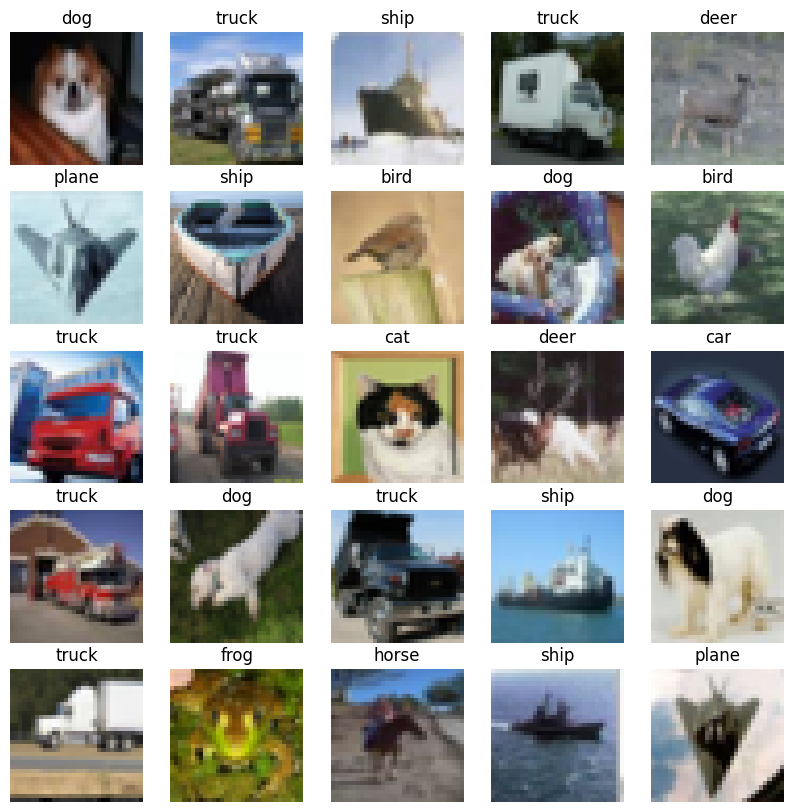

In [4]:
labels = ['plane', 'car', 'bird', 'cat',
           'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

dataiter = iter(train_loader)
images, cat_labels = next(dataiter)

images = images / 2 + 0.5
images_np = images.numpy()
plt.figure(figsize=(10,10))
for i in range(25):
  plt.subplot(5,5,i+1)
  plt.imshow(np.transpose(images_np[i], (1, 2, 0)))
  plt.axis("off")
  plt.title(labels[cat_labels[i].numpy()])
plt.show()

# <font color='#3b4859'>2. L'architecture d'un CNN pour la classification</font>

📚 Dans le cadre d'une tâche de classification, les **réseaux de neurones convolutifs** ou Convolutional Neural Networks (CNNs) sont séparés en 2 blocs distincts :
- Un **bloc d’extraction de features** (pour l'apprentissage des variables)
- Un **bloc de classification** (que l'on appelle Fully-Connected)
<br>


Un CNN peut être représenté de la façon suivante :
<center><img src="https://github.com/datagong/data/blob/main/cnn_archi_.png?raw=true"width="1000"/></center>

Le bloc d'**Extraction de features** est composé de **plusieurs blocs de convolutions**. Un **bloc de convolutions** est composé de :
- une **convolution** qui sert à l'**extraction de features**
- une **fonction d'activation** qui ajoute de la **non-linéarité**
- une **couche de pooling** afin de **réduire la dimensionnalité**

Dans l'exemple suivant nous utiliserons `torch.nn.Sequential` pour implémenter le block de convolution.

In [5]:
conv_block = nn.Sequential(
    nn.Conv2d(3, 16, 5, bias=False),
    nn.ReLU(),
    nn.MaxPool2d(2,2)
)

Le bloc de convolution contient :
- une **couche de convolution** avec les paramètres suivants :
  - input channels : 3
  - output channels : 16
  - taille du kernel : (5,5)
- une fonction d'activation **ReLU**
- un **max-pooling** avec les paramètres suivants :
  - taille du kernel : (2,2)
  - stride : 2

On passe ensuite le batch `images` défini précédemment dans le bloc de convolution.

In [6]:
y = conv_block(images)
print(f"Dimension des feature maps générées : {tuple(y.shape)}")

Dimension des feature maps générées : (64, 16, 14, 14)


Les features maps générées sont de dimension $64\times 16\times 14\times 14$, avec $64$ **la taille du batch**, $16$ **le nombre de features maps** et $14 \times 14$ **la dimension des feature maps**. </br>

On peut visualiser les features générées.
Prenons, par exemple la première image du batch

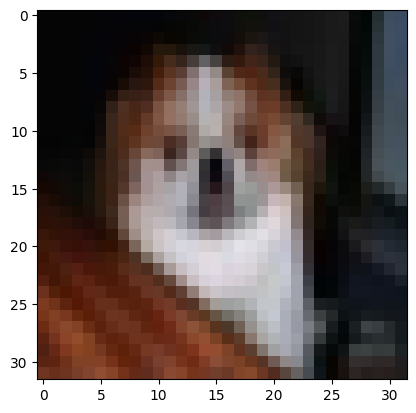

In [7]:






plt.imshow(images[0,...].detach().numpy().transpose(1,2,0))

On visualise les features générées en appelant la fonction suivante `vis_features`

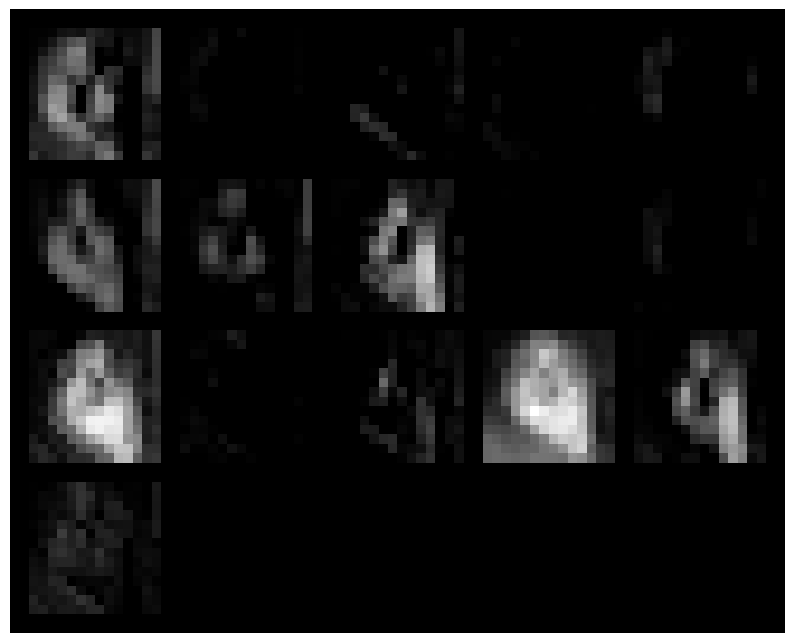

In [8]:
# Visualisation des ouputs de y
def vis_features(y, figsize=(22,20)):
    # Redimensionnement du tenseurs
    out = y.permute(1, 0, 2, 3)
    # Normalisation entre 0 et 1
    out = (out - out.min().expand(out.size())) / (out.max() - out.min()).expand(out.size())
    # Création d'une grille d'images
    out = torchvision.utils.make_grid(out, nrow=5)
    # Conversion en numpy array
    out = np.transpose(out.detach().numpy(), (1, 2, 0))
    # Affichage
    plt.figure(figsize=figsize)
    plt.imshow(out)
    plt.gca().grid(False)
    plt.axis("off")

vis_features(y[0,...].unsqueeze(0), figsize=(10,10))

Il est important de noter que les features extraites ne sont **pas toujours interprétables par l'oeil humain**, mais elles le sont pour le modèle. </br>

Maintenant que vous avez appris à **implémenter un bloc convolutif**, vous pouvez désormais **construire l'architecture d'un CNN**. Il vous suffit d'**assembler plusieurs blocs convolutifs** dans une classe en utilisant `nn.Module` et de finir par **un réseau de neurones** que l'on appelle aussi **Fully-connected**. </br>

La procédure est la suivante :

```python
class CNN(nn.Module):
    def __init__(self):
        super(CNN, self).__init__()
        self.conv_layer1 = nn.Sequential("votre_première_couche")
        self.conv_layer2 = nn.Sequential("votre_deuxième_couche")
        ...
        self.fully_connected = nn.Sequential("réseau_de_neurone")
        

    def forward(self, x):
        x = self.conv_layer1(x) # forward de la 1ere couche
        x = self.conv_layer2(x) ## forward de la 2eme couche
        ...
        x = x.view(x.size(0), -1) # il faut ici flatten le vecteur
        x = self.fully_connected(x)
        return x
```

⚠️ Il faut toujours faire attention aux **dimensions de la sortie du bloc de convolution**. Généralement, il est commun d'**aplatir l'output** (flatten) pour qu'il puisse rentrer dans le **réseau de neurones de classification**.


⚒️ **EXERCICE :** Construisez dans la cellule suivante un CNN avec les paramètres suivants :

- ***Conv layer 1*** :  
  - Convolution avec un filtre de taille $5\times 5$, 16 feature maps - fonction d'activation Tanh
  - max pooling avec un kernel de taille $2\times 2$, stride = 2
- ***Conv layer 2*** :  
  - Convolution avec un filtre de taille $5\times 5$, 128 feature maps - fonction d'activation Tanh
  - max pooling avec un kernel de taille $2\times 2$, stride = 2
- Flatten la sortie en vecteur
- ***Fully Connected*** :  
  - Une couche de 64 neurones - fonction d'activation ReLU
  - Une couche de sortie de 10 neurones


In [9]:
### CODEZ ICI : Remplacez les None par votre code ###

class conv_net(nn.Module):
    def __init__(self):
        super(conv_net, self).__init__()
        self.conv_layer1 = nn.Sequential(
            nn.Conv2d(in_channels=3, out_channels=16, kernel_size=5, stride=1, padding=0),
            nn.Tanh(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        self.conv_layer2 = nn.Sequential(
            nn.Conv2d(in_channels=16, out_channels=128, kernel_size=5, stride=1, padding=0),
            nn.Tanh(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        self.fully_connected = nn.Sequential(
            nn.Linear(in_features=128 * 5 * 5, out_features=64), # 5*5 used to be 4*4
            nn.ReLU(),
            nn.Linear(in_features=64, out_features=10)
        )

    def forward(self, x):
        x = self.conv_layer1(x)
        x = self.conv_layer2(x)
        x = x.view(x.size(0), -1)
        x = self.fully_connected(x)
        return x

### FIN DU CODE ###


Initialisez votre modèle et mappez le au GPU en executant la cellule suivante.

In [10]:
#model = conv_net().to(device) #Found no NVIDIA driver on your system. Please check that you have an NVIDIA GPU and installed a driver from http://www.nvidia.com/Download/index.aspx
device = torch.device('cpu')
model = conv_net().to(device)
print(model)

conv_net(
  (conv_layer1): Sequential(
    (0): Conv2d(3, 16, kernel_size=(5, 5), stride=(1, 1))
    (1): Tanh()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv_layer2): Sequential(
    (0): Conv2d(16, 128, kernel_size=(5, 5), stride=(1, 1))
    (1): Tanh()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (fully_connected): Sequential(
    (0): Linear(in_features=3200, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=10, bias=True)
  )
)


🎉 Féliciations ! Vous avez créée votre premier réseau de neurones convolutif ! </br>

Maintenant, l'**objectif est de l'entraîner**. La **procédure est la même que pour un réseau de neurones classique** fully-connected :  
- choix de l'**optimiseur**
- choix de la **loss**
- implémentation d'une fonction d'**entraînement d'une epoch**
- implémentation d'une fonction de **validation d'une epoch**

# <font color='#3b4859'>3. Le choix de l'optimiseur</font>

Maintenant que vous avez implémenté l'architecture du CNN, il faut choisir l'optimiseur.

Pour rappel, l'objet `torch.optim` contient plusieurs optimiseurs :.
- **Stochastique gradient descent (SGD)** :  `torch.optim.SGD`
- **RMS Prop** :  `torch.optim.RMSprop`
- **Adam** : `torch.optim.Adam`

Ici, nous allons utiliser `torch.optim.SGD`, dont les différents arguments sont :
- Les **paramètres du modèle**
- Le **learning rate**

⚒️ **EXERCICE :** Complétez la cellule suivante en initialisant un optimiseur `SGD` avec un `learning rate` égal à $0.01$.


In [11]:
### CODEZ ICI : Remplacez les None par votre code ###


optimizer = optim.SGD(model.parameters(), lr=0.01)

### FIN DU CODE ###

# <font color='#3b4859'>4. Le choix de fonction de loss</font>

*Rappel sur les fonctions de coût :* </br>

Plusieurs fonctions de coût sont implémentées dans le module `torch.nn`, les principales :
- **binary cross entropy** : classification binaire `nn.BCELoss()`
- **cross entropy** : classification multi-classes `nn.CrossEntropyLoss()`  
- d'autres fonctions de loss classique

Dans notre cas, nous avons un dataset constritué d'images chacune rattachées à une classe, parmi 10 classes. Il s'agit donc d'une **classification multi-classes** : Nous allons donc utiliser la **Cross Entropy**.


⚒️ **EXERCICE :** Complétez la cellule suivante en utilisant la Cross Entropy loss comme `criterion`.


In [12]:
### CODEZ ICI : Remplacez les None par votre code ###

criterion = nn.CrossEntropyLoss()

### FIN DU CODE ###

# <font color='#3b4859'>5. Entraîner une epoch</font>


⚒️ **EXERCICE :** Complétez la fonction `train` qui entraîne le modèle sur l'intégralité des batchs du dataset d'entrainement. </br>

Pour rappel, les différentes étapes à implémenter sont :
- passer les données sur GPU
- ne pas oublier de **ré-initialiser les gradients** à chaque batch
- **forward propagation**
- calcul de la **loss**
- **backpropagation**
- **mise à jour** des poids

⚠️ Ne jamais oublier de spécifier `model.train()` lorsque l'on entraîne un modèle. En effet, cela permet de spécifier que le modèle est en "mode" entraînement.

In [13]:
### CODEZ ICI : Remplacez les None par votre code ###

def train(model, epoch, log_interval=200):
    # Passer le modèle en mode train
    model.train()




    # Boucler sur tous les batch du training set
    for batch_idx, (data, target) in enumerate(train_loader):
        # Passer les données sur GPU
        #data = data.cuda()
        #target = target.cuda()
        #solving the NVIDIA problem again
        device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')





        data = data.to(device)
        target = target.to(device)


        # Ré-initialiser les gradients
        optimizer.zero_grad()

        # Passer les données dans le réseau (forward propagation)
        output = model(data)
        # Calculer la loss
        loss = criterion(output,target)

        # Backpropagation
        loss.backward()

        # Mise à jour des poids
        optimizer.step()

        if batch_idx % log_interval == 0:
            print('Train Epoch: {} [{}/{} ({:.0f}%)]\tLoss: {:.6f}'.format(
                epoch, batch_idx * len(data), len(train_loader.dataset),
                100. * batch_idx / len(train_loader), loss.data.item()))

### FIN DU CODE ###

# <font color='#3b4859'>6. Validation d'une epoch</font>

Une fois le modèle entrainé sur une epoch (c'est à dire sur l'intégralité du dataset de train), il est indispensable de le **valider/évaluer sur les données de validation** (et éventuellement les données d'entrainement). </br>
L'étape validation implique :
- le calcul de la **loss**
- le calcul des **métriques d'évaluation**

La métrique que nous allons utiliser dans cet exercice est l'**Accuracy**, elle est définie de la manière suivante : </br></br>

$$Accuracy = \frac{nombre\ de\ prédictions\ correctes}{nombre\ total\ d'exemples}$$


⚒️ **EXERCICE :** Complétez la fonction `validate` qui entraîne le modèle sur l'intégralité du dataset de train ou de validation. </br>

Résumons les différentes étapes de cette fonction de validation :
- passez les données sur GPU
- **forward propagation**
- calculez la **loss**
- ajoutez  la loss à la liste globale (on veut calculer la loss moyenne)
- calculez les **probabilités pour chaque classe** à partir de la sortie du réseau (**utilisez un Softmax sur la sortie brut du modèle**). Pour rappel, la loss `CrossEntropyLoss` de PyTorch utilise la sortie brute du réseau (les logits)
- calculez la prédiction (la plus grande probabilité parmi toutes les classes)
- calculez le **nombre de prédictions correctes**
</br>

Puis à la fin de la boucle:
- calculez la **loss moyenne**
- calculer l'**accuracy** à partir du **nombre de prédictions correctes**

⚠️ Ne jamais oublier de spécifier `model.eval()` lors de l'étape de validation. En effet, cela permet de spécifier que le modèle est en "mode" évaluation.


💡 Astuces
- Pour le calcul des prédictions à partir des probabilités, on pourra utiliser [`torch.max()`](https://pytorch.org/docs/stable/generated/torch.max.html). Lisez attentivement la documentation. La `torch.max` retourne un `tuple` `(valeur, indice)` qui correspond à la `valeur` maximale et son `indice` dans le tenseur.
- Pour le calcul de l'**accuracy**, on pourra utiliser la fonction [`torch.eq()`](https://pytorch.org/docs/stable/generated/torch.eq.html) qui permet de calculer l'égalité élément à élément entre deux tenseurs. Attention, le tenseur de sortie est un booléen, il faudra adapter le type du tenseur !
- ⚠️ Important : Au-dessus de la fonction, on utilise le décorateur [`@torch.no_grad()`](https://pytorch.org/docs/stable/generated/torch.no_grad.html). Cette fonction permet de garder le paramètre `requires_grad = False` et ainsi de ne pas calculer les gradients au fur et à mesure des opération. En effet, lors de l'étape de **validation**, il n'y a **pas d'étape de back-propagation**, donc pas d'utilité de propager les gradients.
On peut aussi utiliser l'opérateur `torch.no_grad` de la façon suivante :
```python
with torch.no_grad():
      #les calculs que vous souhaitez effectuer
```

In [14]:
### CODEZ ICI : Remplacez les None par votre code ###

@torch.no_grad()
def validate(model, loader, loss_vector, accuracy_vector, step="Validation"):

    # Passer le modèle en mode eval
    model.eval()
    # Initialiser les valeurs de loss et de prédiction correctes
    val_loss, correct = 0, 0

    # Boucler sur tous les batch du dataset
    for batch_idx, (data, target) in enumerate(train_loader):
        # Passez les données sur GPU
        data = data.cuda()
        target = target.cuda()

        # Passez les données dans le réseau (forward propagation)
        output = model(data)

        # Ajoutez la loss du batch à la liste val_loss (utiliser ici .data.item pour obtenir la valeur)
        val_loss += criterion(output, target).item()

        # Calculez les prédictions
        pred_softmax = torch.softmax(output, dim=1)

        # Passez les outputs logits
        pred = pred_softmax.argmax(dim=1, keepdim=True)

        # Calculez le nombre de prédiction correctes et on ajoute à la liste correct
        correct += pred.eq(target.view_as(pred)).sum().item()

    # Moyenner la loss par le nombre d'exemples
    val_loss = val_loss / len(loader.dataset)

    loss_vector.append(val_loss)

    # Calculez l'accuracy, formule  100 * "predictions correctes" / "nombre d'exemples"
    accuracy = 100. * correct / len(loader.dataset)
    accuracy_vector.append(accuracy)

    print('{} set: Average loss: {:.4f}, Accuracy: {}/{} ({:.0f}%)\n'.format(
        step, val_loss, correct, len(loader.dataset), accuracy))

### FIN DU CODE ###

Maintenant que vous avez implémenté avec succès les fonctions `train` et `validate`, il est temps d'entraîner votre réseau.

# <font color='#3b4859'>7. Entrainement du modèle</font>

Exécuter la cellule suivante pour entraîner votre réseau de neurones.
On entraîne le modèle sur $20$ epochs en appliquant le schéma suivant.

A chaque epoch, on itère :
- étape de **training** sur le **dataset de train**
- **validation** sur le **dataset de train**
- **validation** sur le **dataset de validation**

⚠️ Il est important de monitorer la **loss** et les métriques (ici l'**accuracy**) tout au long du training, car elles donnent des informations importantes sur les **performances du modèle entraîné**. </br>

Dans cet exemple, nous utilisons des listes pour stocker les valeurs des loss et métriques pour chaque epoch.

Le script ci-dessous peut prendre 15min à s'exécuter.

In [15]:
%%time


# Définir le dispositif d'exécution : 'cuda' si disponible, sinon 'cpu'
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Déplacer le modèle sur le périphérique sélectionné
model = conv_net().to(device)

epochs = 30

loss_training, acc_training = [], []
loss_validation, acc_validation = [], []

for epoch in range(1, epochs + 1):
    train(model, epoch)

    validate(model, train_loader, loss_training, acc_training, "Training")
    validate(model, validation_loader, loss_validation, acc_validation, "Validation")


Train Epoch: 1 [0/50000 (0%)]	Loss: 2.306532
Train Epoch: 1 [12800/50000 (26%)]	Loss: 2.289899
Train Epoch: 1 [25600/50000 (51%)]	Loss: 2.311114
Train Epoch: 1 [38400/50000 (77%)]	Loss: 2.303480
Training set: Average loss: 0.0361, Accuracy: 4692/50000 (9%)

Validation set: Average loss: 0.1804, Accuracy: 4692/10000 (47%)

Train Epoch: 2 [0/50000 (0%)]	Loss: 2.317049
Train Epoch: 2 [12800/50000 (26%)]	Loss: 2.303431
Train Epoch: 2 [25600/50000 (51%)]	Loss: 2.290905
Train Epoch: 2 [38400/50000 (77%)]	Loss: 2.292808
Training set: Average loss: 0.0361, Accuracy: 4692/50000 (9%)

Validation set: Average loss: 0.1804, Accuracy: 4692/10000 (47%)

Train Epoch: 3 [0/50000 (0%)]	Loss: 2.301272
Train Epoch: 3 [12800/50000 (26%)]	Loss: 2.316217
Train Epoch: 3 [25600/50000 (51%)]	Loss: 2.312031
Train Epoch: 3 [38400/50000 (77%)]	Loss: 2.312659
Training set: Average loss: 0.0361, Accuracy: 4692/50000 (9%)

Validation set: Average loss: 0.1804, Accuracy: 4692/10000 (47%)

Train Epoch: 4 [0/50000 (0%)

# <font color='#3b4859'>8. Les courbes d'entrainement </font>

Maintenant que vous avez entraîné votre modèle, il faut **regarder les courbes d'apprentissage**, car elles sont **importantes pour la validation d'un modèle**. </br>

Executez la cellule suivant pour mettre en évidence les courbes d'apprentissage de votre entraînement. </br>

❓ Quelles informations importantes pouvez vous en tirer ?

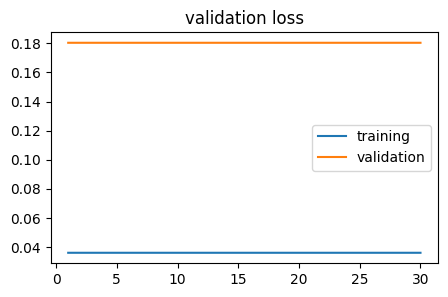

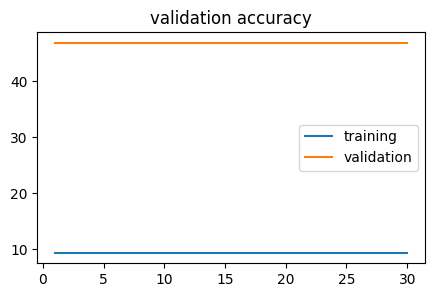

In [17]:
plt.figure(figsize=(5,3))
plt.plot(np.arange(1,epochs+1), loss_training)
plt.plot(np.arange(1,epochs+1), loss_validation)
plt.legend(['training','validation'])
plt.title('validation loss')

plt.figure(figsize=(5,3))
plt.plot(np.arange(1,epochs+1), acc_training)
plt.plot(np.arange(1,epochs+1), acc_validation)
plt.legend(['training','validation'])
plt.title('validation accuracy');

💡 On peut observer sur les courbes d'apprentissage, qu'au fur et à mesure de l'entraînement, **les courbes sur le dataset de train continuent à progresser, tandis que celles du dataset de validation semblent peu à peu stagner**. </br>

Les performances sur l'ensemble de train sont bien supérieures à celles sur l'ensemble de validation : **forte suspicion d'overfitting** !

# <font color='#3b4859'>9. Comment prévenir l'overfitting ?</font>

📚 **Rappels de cours** </br>
L’un des fondamentaux de l’entrainement d’un modèle de Deep Learning est d’éviter le **sur-apprentissage ou overfitting** en anglais.

L'overfitting se traduit de la façon suivante :
- Le **modèle est trop proche des données d’entrainement**
- Les performances du modèle sur d’autres données sont mauvaises

Il existe plusieurs procédures pour éviter le sur-apprentissage :
- la **régularisation**
- l'utilisation du **drop-out**
- l'**augmentation de données** ou data augmentation (souvent utilisée en Computer Vision). </br>

Dans cette partie, nous allons utiliser la même architecture que précédemment, mais l'entraîner en utilisant :
- du **drop-out**
- de la **data-augmentation**

## <font color='#3b4859'>9.1. L'augmentation de données ou data augmentation</font>  

Dans cette partie nous allons redéfinir le dataset en y ajoutant un certain nombre de transformations. Le but est d'agrandir la taille du dataset en évitant d'utiliser plusieurs fois les mêmes exemples et ainsi d'éviter le surapprentissage. </br>

Un certain nombre d'augmentations sont implémentées dans `torchvision.transforms` et sont adaptées aux objets `Dataset` de PyTorch. Vous pouvez regarder la [documentation officielle de PyTorch](https://pytorch.org/vision/stable/transforms.html), pour voir toutes les transformations proposées. Vous trouverez par ailleurs un [exemple](https://pytorch.org/vision/stable/auto_examples/plot_transforms.html#sphx-glr-auto-examples-plot-transforms-py) qui regroupe et qui illustre toutes les transformations proposées dans le module `torchvision.transforms`. </br>

Dans notre exemple, nous allons utiliser les deux transformations suivantes :

- [`RandomHorizontalFlip`](https://pytorch.org/vision/stable/generated/torchvision.transforms.RandomHorizontalFlip.html#torchvision.transforms.RandomHorizontalFlip) qui permet de renverser l'image horizontalement de façon aléatoire selon une probabilité définie
- [`RandomRotation`](https://pytorch.org/vision/stable/generated/torchvision.transforms.RandomRotation.html#torchvision.transforms.RandomRotation) qui permet d'effectuer une rotation de l'image de façon aléatoire dans un interval d'angulation défini



⚠️ La **data augmentation** s'applique **uniquement sur le dataset de training**, **pas sur le dataset de validation**.



In [18]:
data_augmentation = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
    transforms.RandomHorizontalFlip(p=0.2),
    transforms.RandomRotation(degrees=(-10,10)),
])

data_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])

# Création des datasets
train_dataset = datasets.CIFAR10(root='.', train=True, download=True, transform=data_augmentation)
validation_dataset = datasets.CIFAR10(root='.', train=False, download=True, transform=data_transform)

batch_size = 64

# Création des DataLoader de training et validation
train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=0)
validation_loader  = torch.utils.data.DataLoader(validation_dataset, batch_size=batch_size, shuffle=False, num_workers=0)


Files already downloaded and verified
Files already downloaded and verified


On peut observer ci-dessous les images générées par **augmentation de données** sur le dataset de train.

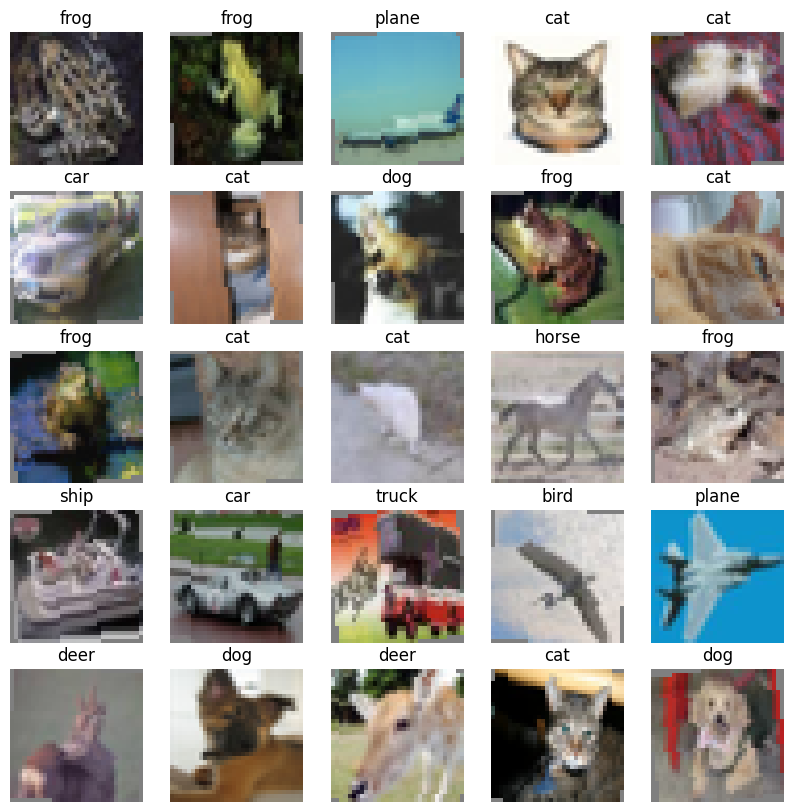

In [19]:
labels = ['plane', 'car', 'bird', 'cat',
           'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

dataiter = iter(train_loader)
images, cat_labels = next(dataiter)

images = images / 2 + 0.5
images_np = images.numpy()
plt.figure(figsize=(10,10))
for i in range(25):
  plt.subplot(5,5,i+1)
  plt.imshow(np.transpose(images_np[i], (1, 2, 0)))
  plt.axis("off")
  plt.title(labels[cat_labels[i].numpy()])
plt.show()

On observe que les images ont toutes des **rotations d'angulation différentes allant de -10 à 10 degrés**.

## <font color='#3b4859'>9.2. Le drop-out</font>  

📚 **Rappel de cours**

Une deuxième méthode pour prévenir le **surapprentissage** est l'utilisation de ce qu'on appelle le **drop-out**.
Cette méthode **s'applique aux réseaux de neurones traditionnels** de type fully-connected. Ainsi, dans notre réseau, il s'applique au sein du bloc de classification. </br>

Le **drop-out** consiste à **désactiver aléatoirement des neurones lors de l’apprentissage à chaque itération**. Ainsi, les neurones désactivés ne contribuent plus aux forward et backward propagations. Le drop-out **équivaut à entrainer un modèle différent à chaque itération**.

⚠️ Le **drop-out ne s'applique qu'au moment de l’entrainement**, pas lors de l'étape de validation, ni lors de l'étape de prédiction. Il est important ici de ne pas oublier de spécifier si le modèle est en mode `train` ou en mode `eval`.

L'implémentation du Drop-out en PyTorch est implémenté dans le module `torch.nn`. </br>

La fonction `torch.nn.Dropout` prend en argument une probabilité `p` qui correspond à la proportion de neurones à désactiver. </br>

Le **drop-out s'insère juste après une couche fully connected**, de la façon suivante :



```python
class conv_net(nn.Module):
    def __init__(self):
        super(conv_net, self).__init__()
        self.conv_layer1 = "votre couche de convolution 1"
        self.conv_layer2 = "votre couche de convolution 1"
        self.fully_connected1 = "votre couche fully connected 1"
        self.fully_connected2 = "votre couche fully connected 2"
        

    def forward(self, x):
        x = self.conv_layer1(x)
        x = self.conv_layer2(x)
        x = x.view(x.size(0), -1)
        x = self.fully_connected1(x)
        # Ajoutez une couche de drop-out
        x = nn.Dropout(p=0.3)
        x = self.fully_connected2(x)
        # Ajoutez une couche de drop-out
        x = nn.Dropout(p=0.3)
        return x
```

Dans cet exemple, nous allons reprendre l'implémentation de notre modèle `conv_net` et ajouter des couches de drop-out.

⚒️ **EXERCICE :**
Complétez l'architecture de modèle suivant et **ajoutez une couche de drop-out** à un endroit spécifiquement choisi. Vous utiliserez une couche de `nn.Dropout` avec un paramètre `p=0.2`.

💡 N.B. On ne peut pas appliquer de drop-out à la dernière couche du réseau.


In [21]:
### CODEZ ICI : Remplacez les None par votre code ###

class conv_net_dropout(nn.Module):
    def __init__(self):
        super(conv_net_dropout, self).__init__()
        self.conv_layer1 = nn.Sequential(
              nn.Conv2d(3, 16, 5, bias=False),
              nn.Tanh(),
              nn.MaxPool2d(kernel_size=2, stride=2))
        self.conv_layer2 = nn.Sequential(
              nn.Conv2d(16, 128, 5, bias = False),
              nn.Tanh(),
              nn.MaxPool2d(kernel_size=2, stride=2))

        self.fully_connected1 = nn.Linear(128*5*5,64)
        self.fully_connected2 = nn.Linear(64,10)

        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(p=0.2)



    def forward(self, x):
        # bloc convolutif
        x = self.conv_layer1(x)
        x = self.conv_layer2(x)
        x = x.view(x.size(0), -1)

        # bloc fully-connected
        x = self.fully_connected1(x)
        x = self.relu(x)
        x = self.dropout(x)
        x = self.fully_connected2(x)


        return x

### FIN DU CODE ###

In [22]:
images, labels = next(iter(train_loader))

## <font color='#3b4859'>9.3. Entraînement du modèle</font>  

Nous allons maintenant entraîner le **modèle avec drop-out**, sur le **dataset de train avec data-augmentation**. </br>

Dans la cellule suivante on **initialise le modèle et l'optimizer** à partir des poids du modèle. Et on redéfinit le `criterion`.  

In [23]:
model_dropout = conv_net_dropout().to(device)
optimizer = torch.optim.SGD(model_dropout.parameters(), lr=0.01)

criterion = nn.CrossEntropyLoss()

model_dropout(images.cuda()).shape

torch.Size([64, 10])

Entrainons maintenant `model_droupout` en utilisant les fonction `train` et `validate` implémentées précédemment.

Le script ci-dessous peut prendre 40min à s'exécuter.

In [26]:
%%time
epochs = 30

loss_training, acc_training = [], []
loss_validation, acc_validation = [], []

for epoch in range(1, epochs + 1):
    train(model_dropout,epoch)

    validate(model_dropout, train_loader, loss_training, acc_training, "Training")
    validate(model_dropout, validation_loader, loss_validation, acc_validation, "Validation")

Train Epoch: 1 [0/50000 (0%)]	Loss: 0.716017


KeyboardInterrupt: 

## <font color='#3b4859'>9.4. Évaluation des courbes d'entraînement et conclusion</font>

Exécutez la cellule ci-dessous pour observer les courbes d'apprentissage et **évaluez les performances du modèle**.

❓ Que constatez vous ?

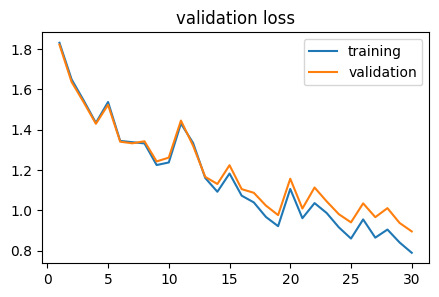

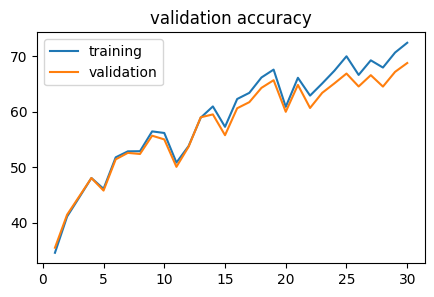

In [ ]:
plt.figure(figsize=(5,3))
plt.plot(np.arange(1,epochs+1), loss_training)
plt.plot(np.arange(1,epochs+1), loss_validation)
plt.legend(['training','validation'])
plt.title('validation loss')

plt.figure(figsize=(5,3))
plt.plot(np.arange(1,epochs+1), acc_training)
plt.plot(np.arange(1,epochs+1), acc_validation)
plt.legend(['training','validation'])
plt.title('validation accuracy');

💡 Les courbes d'apprentissages sur les datasets de training et de validation montrent clairement que l'ajout du **drop-out** et de l'**augmentation de données** ont permis de **résoudre la problématique d'overfitting**.

# <font color='#3b4859'>10. Introduction au Transfer Learning</font>  

📚 **Rappel de cours** </br>
Les **CNNs ont besoin de beaucoup d’images** pour être entraînés et obtenir de bonnes performances.
Lorsque le dataset d’entraînement ne contient **pas assez d’image**, il est courant d’utiliser le **transfer learning**.

Le **transfer learning** permet d’**utiliser l’extraction de features de réseaux pré-entraînés sur des nouvelles images**. On peut ainsi tirer parti d'un modèle ayant été entraîné sur la même tâche ou une tâche similaire.


<br>
<center><img src="https://github.com/datagong/data/blob/main/transfer_learning_.png?raw=true"width="1000"/></center>



Dans cette partie, nous allons **entraîner un CNN en utilisant le transfer learning** sur la tâche de classification de **CIFAR10**. </br>


`torchvision` met à disposition des models pré-entrainés pour la classification ainsi que d'autres tâches (détection, segmentation, etc). Vous trouverez la liste des modèles pré-entraîné ici : [lien](https://pytorch.org/vision/stable/models.html#classification).

Dans cet exemple, nous allons en prendre un ayant une arhitecture classique et pas trop profonde pour notre tâche de transfer learning : le resnet18 ([lien vers le papier](https://arxiv.org/pdf/1512.03385.pdf), [lien vers l'implémentation `torchvision`](https://pytorch.org/vision/stable/models/generated/torchvision.models.resnet18.html#torchvision.models.resnet18)).

Ce modèle a été entraîné sur les images de [ImageNet](https://fr.wikipedia.org/wiki/ImageNet) qui est l'un des datasets les plus célèbre en Computer Vision et qui contient plusieurs millions d'images représentant 1000 classes. </br>

L'idée du transfer learning est d'**extraire les features apprises par le bloc de convolutions** et d'effectuer ce que l'on appelle un **fine-tuning** de tête de classification, c'est à dire le bloc de fully connected. </br>

Commençons par importer le modèle pré-entraîné.

In [ ]:
from torchvision import models

pretrained_model = models.resnet18(pretrained=True)
pretrained_model

/usr/local/lib/python3.9/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.9/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth
100%|██████████| 44.7M/44.7M [00:00<00:00, 137MB/s]


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

Voici un schéma de l'architecture du modèle resnet18 que nous venons d'importer.

<br>
<center><img src="https://github.com/datagong/data/blob/main/resnet18Archi.png?raw=true"width="700"/></center>


La dernière couche du modèle, nommée `fc`, est celle que nous allons modifier. </br>

Le transfer learning ou apprentissage par transfert peut être utilisé de deux façons dans notre exemple :
- on fine-tune le réseau et on entraîne l'intégralité du modèle sur le dataset
- on entraîne **que la partie fully connected** et **on freeze le bloc convolutif**. Cela permet de se servir du réseau convolutif comme extracteur de features. </br>

Dans cet exemple nous n'allons pas entraîner tout le réseau, mais **uniquement la partie fully connected**. Cela permet de tirer parti de ce qui a été appris précédemment par le réseau et de ne pas avoir un temps d'entraînement trop long car on ne propage pas les gradient sur l'intégralité des couches. </br>

La procédure est la suivante :
- on freeze l'intégralité des couches, en spécifiant `requires_grad = False`
- on récupère le **nombre de features en sortie du dernier bloc de convolution** que l'on appelle `num_features`
- on créée une couche fully connected de type `torch.nn.Linear` avec en entrée `num_features` et en sortie le nombre de classes de notre dataset (ici 10)

In [ ]:
num_features = pretrained_model.fc.in_features

for param in pretrained_model.parameters():
    param.requires_grad = False

pretrained_model.fc = nn.Linear(num_features, 10)
pretrained_model = pretrained_model.to(device)

param_entrainables = sum(p.numel() for p in pretrained_model.parameters() if p.requires_grad)
print(f"Le modèle a {param_entrainables} paramètre entraînable")

Le modèle a 5130 paramètre entraînable


Il y a 5130 paramètres entraînables, ce qui signifie bien que seule la couche fully-connected est entraînée. </br>

On initialise ensuite l'optimiseur à partir des poids du modèle.

In [ ]:
optimizer = torch.optim.SGD(pretrained_model.parameters(), lr=0.01)

Entrainez le modèle sur $10$ epochs, avec les fonction `train` et `validate` définies précédemment.

Ce script peut prendre 40min à s'exécuter.

In [ ]:
%%time
epochs = 30

loss_training, acc_training = [], []
loss_validation, acc_validation = [], []

for epoch in range(1, epochs + 1):
    train(pretrained_model,epoch)

    validate(pretrained_model, train_loader, loss_training, acc_training, "Training")
    validate(pretrained_model, validation_loader, loss_validation, acc_validation, "Validation")

Train Epoch: 1 [0/50000 (0%)]	Loss: 2.560627
Train Epoch: 1 [12800/50000 (26%)]	Loss: 1.782281
Train Epoch: 1 [25600/50000 (51%)]	Loss: 1.865464
Train Epoch: 1 [38400/50000 (77%)]	Loss: 1.860250
Training set: Average loss: 1.6943, Accuracy: 20176/50000 (40%)

Validation set: Average loss: 1.6769, Accuracy: 4175/10000 (42%)

Train Epoch: 2 [0/50000 (0%)]	Loss: 1.832275
Train Epoch: 2 [12800/50000 (26%)]	Loss: 1.755443
Train Epoch: 2 [25600/50000 (51%)]	Loss: 1.605291
Train Epoch: 2 [38400/50000 (77%)]	Loss: 1.744754
Training set: Average loss: 1.6711, Accuracy: 21078/50000 (42%)

Validation set: Average loss: 1.6639, Accuracy: 4251/10000 (43%)

Train Epoch: 3 [0/50000 (0%)]	Loss: 1.901611
Train Epoch: 3 [12800/50000 (26%)]	Loss: 1.813984
Train Epoch: 3 [25600/50000 (51%)]	Loss: 1.663822
Train Epoch: 3 [38400/50000 (77%)]	Loss: 1.871719
Training set: Average loss: 1.6581, Accuracy: 20777/50000 (42%)

Validation set: Average loss: 1.6205, Accuracy: 4357/10000 (44%)

Train Epoch: 4 [0/5000

Évaluez le modèle à partir des courbes d'apprentissage. </br>

Comparez les **résultats du modèle obtenu en utilisant l'apprentissage par transfert** aux résultats des premiers modèles que vous avez entraînés. </br>

❓ Que constatez-vous ?

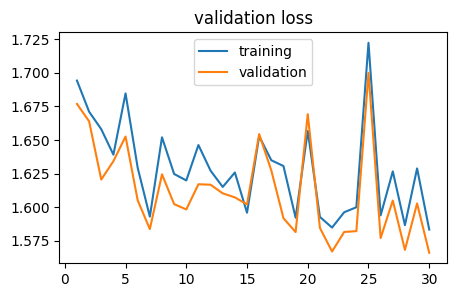

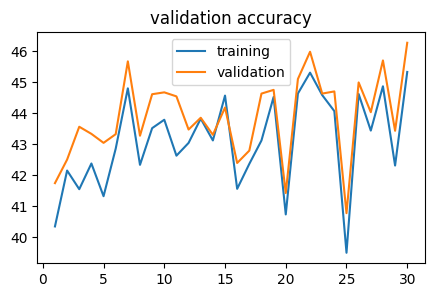

In [ ]:
plt.figure(figsize=(5,3))
plt.plot(np.arange(1,epochs+1), loss_training)
plt.plot(np.arange(1,epochs+1), loss_validation)
plt.legend(['training','validation'])
plt.title('validation loss')

plt.figure(figsize=(5,3))
plt.plot(np.arange(1,epochs+1), acc_training)
plt.plot(np.arange(1,epochs+1), acc_validation)
plt.legend(['training','validation'])
plt.title('validation accuracy');

Les **performances du modèle entraîné avec transfer learning sont très bonnes** et ce, après quelques itérations seulement. </br>

En effet, l'utilisation d'un modèle pré-entraîné permet de **tirer parti des features qui ont été apprises lors d'un précédent entrainement** et de s'en servir comme levier pour une tâche proche ou similaire. </br>